# Reconocimiento de actividad física con señales de sensores

### Implementación de un modelo de deep learning con Keras y TensorFlow

**Alumno:** Yael Michel García López
**Matrícula:** A01750911
**Materia:** Inteligencia artificial avanzada para la ciencia de datos

---

**Problema:** clasificar qué actividad física está realizando una persona a partir
de las señales crudas del acelerómetro y el giroscopio de su teléfono.

**Dataset:** Human Activity Recognition Using Smartphones (UCI Machine Learning
Repository). 10,299 ventanas de señales de 30 voluntarios reales.

**Arquitectura:** red híbrida Conv1D + LSTM bidireccional.

**Resultado:** 90.91% de exactitud en el conjunto de prueba,
formado por 9 personas que el modelo nunca vio durante el entrenamiento.

## 0. Preparación del entorno

In [1]:
import json
import os
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # silencia avisos informativos de TF

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)          # fija numpy, random y tensorflow

CARPETA_DATOS = Path("datos")
CACHE = CARPETA_DATOS / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

ACTIVIDADES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
               "SITTING", "STANDING", "LAYING"]

# Las 9 señales inerciales, en el orden en que se apilan como canales
SENIALES = ["body_acc_x", "body_acc_y", "body_acc_z",
            "body_gyro_x", "body_gyro_y", "body_gyro_z",
            "total_acc_x", "total_acc_y", "total_acc_z"]

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["figure.dpi"] = 110

print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "sin GPU, se usa CPU")

TensorFlow: 2.21.0
Keras     : 3.15.1


GPU        : sin GPU, se usa CPU


## 1. Introducción

### El problema

Un teléfono moderno lleva encima un acelerómetro y un giroscopio que registran
decenas de lecturas por segundo. El problema que se aborda aquí es traducir esas
señales en una respuesta útil: **¿qué está haciendo físicamente la persona que
trae el teléfono?** Concretamente se distinguen seis actividades: caminar, subir
escaleras, bajar escaleras, estar sentado, estar de pie y estar acostado.

Es un problema de **clasificación multiclase sobre series de tiempo
multivariadas**. La entrada no es una tabla de atributos ni una imagen, sino una
ventana de 128 lecturas consecutivas en 9 canales simultáneos.

### Por qué es relevante

El reconocimiento de actividad física es la base de varias aplicaciones que ya
están en uso:

- **Monitoreo de adultos mayores.** Detectar que alguien pasó de estar de pie a
  estar acostado en un instante, y que ya no se levanta, es la señal que usan los
  sistemas de detección de caídas.
- **Rehabilitación y fisioterapia.** Verificar si el paciente efectivamente hizo
  los ejercicios prescritos, sin depender de que los reporte él mismo.
- **Salud preventiva.** Medir minutos reales de actividad moderada al día, que es
  la métrica que recomienda la OMS, en lugar de contar pasos sin contexto.
- **Eficiencia energética del dispositivo.** Un teléfono que sabe que su dueño
  está acostado puede apagar sensores y ahorrar batería.

Lo que las une es que ninguna puede resolverse pidiéndole al usuario que registre
manualmente lo que hace. Tiene que inferirse de los sensores.

### Por qué deep learning y no un modelo clásico

El dataset trae, además de las señales crudas, 561 atributos ya calculados por los
autores (medias, desviaciones, energía por banda de frecuencia, correlaciones).
Con esos atributos un SVM o un Random Forest funcionan bien, pero **requirieron
que un experto en procesamiento de señales decidiera qué medir**.

Este trabajo usa deliberadamente **las señales crudas**, no los 561 atributos. La
razón es que ahí está la ventaja real del deep learning sobre series de tiempo:
las capas convolucionales aprenden por su cuenta qué patrones locales importan, y
las recurrentes aprenden cómo se ordenan en el tiempo. No hay ingeniería de
atributos manual en ninguna parte de este notebook.

### Lo que hace este notebook

1. Descarga el dataset de UCI y carga las 9 señales inerciales crudas.
2. Separa los datos en entrenamiento, validación y prueba **por persona**, no por
   ventana, lo cual es indispensable aquí y se explica en la sección 2.
3. Entrena una red Conv1D + LSTM bidireccional y diagnostica su desempeño.
4. Corrige el problema detectado con una segunda iteración y compara.
5. Evalúa el modelo final en el conjunto de prueba.
6. Expone una función que clasifica ventanas nuevas.

## 2. Datos

### 2.1 Fuente y descripción

| | |
|---|---|
| **Nombre** | Human Activity Recognition Using Smartphones |
| **Fuente** | [UCI Machine Learning Repository, dataset 240](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones) |
| **Autores** | Anguita et al., Universitat Politècnica de Catalunya |
| **Sujetos** | 30 voluntarios de 19 a 48 años |
| **Dispositivo** | Samsung Galaxy S II sujeto a la cintura |
| **Frecuencia** | 50 Hz |
| **Ventanas** | 10,299 de 2.56 segundos con 50% de traslape |
| **Clases** | 6 actividades |

Cada ventana contiene **128 lecturas** (2.56 s a 50 Hz) de **9 canales**:
aceleración corporal en x, y, z; velocidad angular en x, y, z; y aceleración total
en x, y, z. La diferencia entre aceleración "corporal" y "total" es que a la
primera ya se le restó la gravedad.

Este dataset cumple las dos restricciones del entregable: **son datos reales**
medidos con personas y sensores físicos, y **no es un toy dataset** como MNIST, ni
uno de los ejemplos vistos en clase.

In [2]:
URL_DATASET = ("https://archive.ics.uci.edu/static/public/240/"
               "human+activity+recognition+using+smartphones.zip")

RAIZ = CARPETA_DATOS / "UCI HAR Dataset"


def descargar_dataset():
    """Descarga y descomprime el dataset si no está ya en disco.

    El zip que publica UCI contiene a su vez otro zip, por eso la doble
    descompresión.
    """
    if RAIZ.exists():
        print("El dataset ya está en disco:", RAIZ.resolve())
        return

    CARPETA_DATOS.mkdir(exist_ok=True)
    zip_externo = CARPETA_DATOS / "har_original.zip"

    if not zip_externo.exists():
        print("Descargando desde UCI (unos 58 MB)...")
        peticion = urllib.request.Request(
            URL_DATASET, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(peticion, timeout=300) as r, \
                open(zip_externo, "wb") as f:
            shutil.copyfileobj(r, f)

    with zipfile.ZipFile(zip_externo) as z:
        internos = [n for n in z.namelist() if n.lower().endswith(".zip")]
        with zipfile.ZipFile(__import__("io").BytesIO(z.read(internos[0]))) as z2:
            z2.extractall(CARPETA_DATOS)

    shutil.rmtree(CARPETA_DATOS / "__MACOSX", ignore_errors=True)
    print("Listo:", RAIZ.resolve())


descargar_dataset()

El dataset ya está en disco: C:\Users\yaelgl\Desktop\spti\modulo 5\datos\UCI HAR Dataset


In [3]:
def leer_matriz(ruta):
    """Lee un archivo de texto separado por espacios.

    Se usa pandas y no np.loadtxt porque los archivos de señales pesan 15 MB
    cada uno y read_csv es alrededor de 30 veces más rápido.
    """
    return pd.read_csv(ruta, sep=r"\s+", header=None).to_numpy(dtype="float32")


def cargar_particion(particion):
    """Devuelve (X, y, sujetos) de 'train' o 'test'.

    X queda con forma (ventanas, 128, 9): las 9 señales inerciales apiladas como
    canales. Se guarda caché en .npy porque parsear el texto tarda alrededor de
    un minuto y se repite en cada ejecución del notebook.
    """
    rutas_cache = [CACHE / f"{n}_{particion}.npy" for n in ("X", "y", "s")]
    if all(r.exists() for r in rutas_cache):
        return tuple(np.load(r) for r in rutas_cache)

    carpeta = RAIZ / particion / "Inertial Signals"
    X = np.stack([leer_matriz(carpeta / f"{s}_{particion}.txt")
                  for s in SENIALES], axis=-1)
    y = leer_matriz(RAIZ / particion / f"y_{particion}.txt").ravel().astype("int32") - 1
    s = leer_matriz(RAIZ / particion / f"subject_{particion}.txt").ravel().astype("int32")

    for ruta, arreglo in zip(rutas_cache, (X, y, s)):
        np.save(ruta, arreglo)
    return X, y, s


t0 = time.perf_counter()
X_oficial, y_oficial, sujetos_oficial = cargar_particion("train")
X_prueba, y_prueba, sujetos_prueba = cargar_particion("test")
print(f"carga: {time.perf_counter() - t0:.1f} s")
print()
print("Partición oficial de entrenamiento:", X_oficial.shape)
print("Partición oficial de prueba       :", X_prueba.shape)
print()
print("Una ventana es una matriz de", X_oficial.shape[1], "lecturas x",
      X_oficial.shape[2], "canales")

carga: 0.0 s

Partición oficial de entrenamiento: (7352, 128, 9)
Partición oficial de prueba       : (2947, 128, 9)

Una ventana es una matriz de 128 lecturas x 9 canales


### 2.2 Análisis exploratorio

In [4]:
resumen = pd.DataFrame({
    "actividad": ACTIVIDADES,
    "n_entrenamiento": [int((y_oficial == i).sum()) for i in range(6)],
    "n_prueba": [int((y_prueba == i).sum()) for i in range(6)],
})
resumen["% entrenamiento"] = (resumen["n_entrenamiento"] /
                              len(y_oficial) * 100).round(2)
resumen["% prueba"] = (resumen["n_prueba"] / len(y_prueba) * 100).round(2)

print("Distribución de clases")
print(resumen.to_string(index=False))
print()
print(f"Total de ventanas: {len(y_oficial) + len(y_prueba):,}")
print(f"Clase más frecuente: {resumen['% entrenamiento'].max():.2f}%  |  "
      f"menos frecuente: {resumen['% entrenamiento'].min():.2f}%")

Distribución de clases
         actividad  n_entrenamiento  n_prueba  % entrenamiento  % prueba
           WALKING             1226       496            16.68     16.83
  WALKING_UPSTAIRS             1073       471            14.59     15.98
WALKING_DOWNSTAIRS              986       420            13.41     14.25
           SITTING             1286       491            17.49     16.66
          STANDING             1374       532            18.69     18.05
            LAYING             1407       537            19.14     18.22

Total de ventanas: 10,299
Clase más frecuente: 19.14%  |  menos frecuente: 13.41%


In [5]:
# Estadísticos por canal: determinan si hace falta normalizar
estadisticos = pd.DataFrame({
    "canal": SENIALES,
    "media": [X_oficial[:, :, i].mean() for i in range(9)],
    "desv_est": [X_oficial[:, :, i].std() for i in range(9)],
    "minimo": [X_oficial[:, :, i].min() for i in range(9)],
    "maximo": [X_oficial[:, :, i].max() for i in range(9)],
}).round(4)

print("Estadísticos por canal (partición de entrenamiento)")
print(estadisticos.to_string(index=False))

Estadísticos por canal (partición de entrenamiento)
      canal   media  desv_est  minimo  maximo
 body_acc_x -0.0006    0.1948 -1.2322  1.2999
 body_acc_y -0.0003    0.1224 -1.3453  0.9760
 body_acc_z -0.0003    0.1069 -1.3647  1.0669
body_gyro_x  0.0005    0.4068 -4.7337  4.1555
body_gyro_y -0.0008    0.3819 -5.9743  5.7461
body_gyro_z  0.0001    0.2557 -2.7630  2.3660
total_acc_x  0.8047    0.4141 -0.4666  2.1976
total_acc_y  0.0288    0.3910 -1.5821  1.2174
total_acc_z  0.0865    0.3578 -1.6396  1.2814


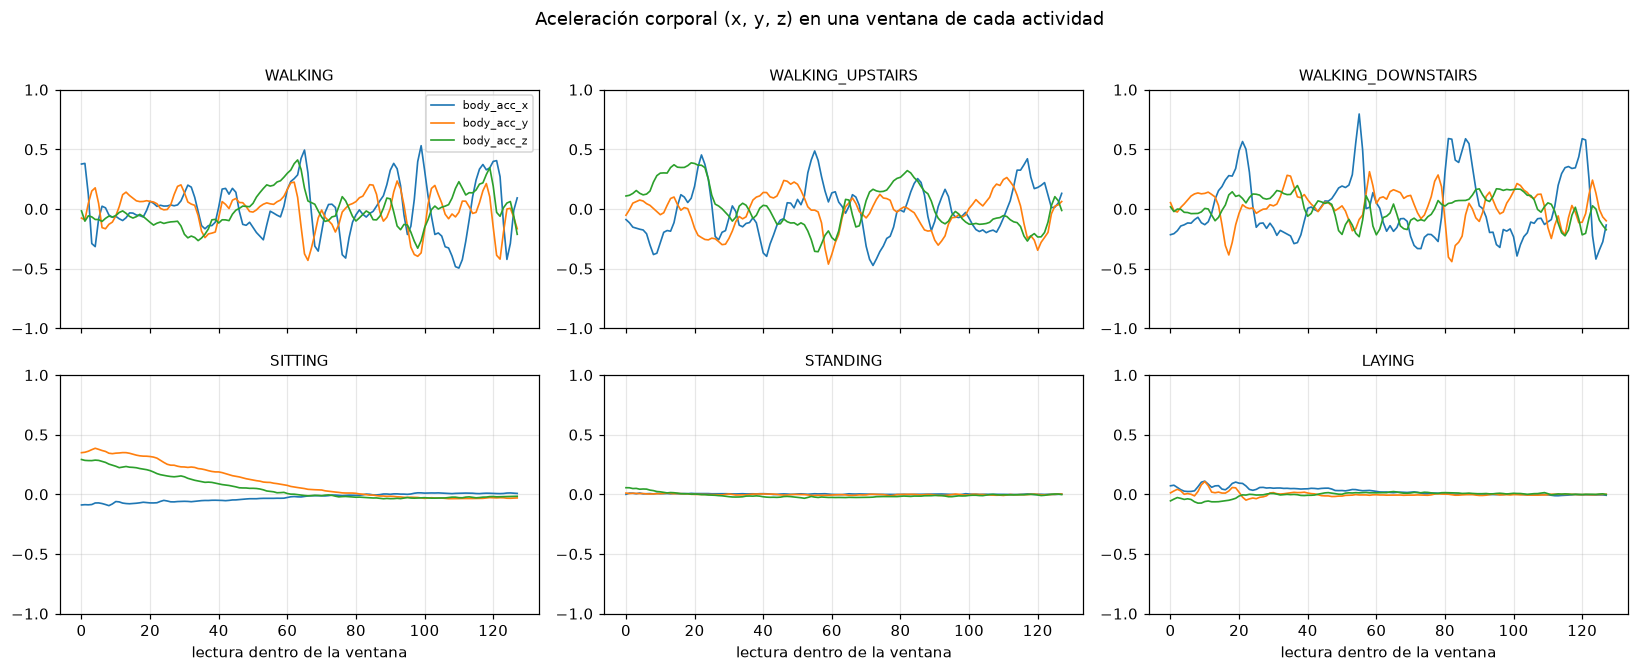

In [6]:
# Una ventana de ejemplo por actividad, para ver qué tan distintas son las señales
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for i, (ax, actividad) in enumerate(zip(axes.ravel(), ACTIVIDADES)):
    indice = int(np.where(y_oficial == i)[0][0])
    ventana = X_oficial[indice]
    for canal, color in [(0, "tab:blue"), (1, "tab:orange"), (2, "tab:green")]:
        ax.plot(ventana[:, canal], lw=1.1, color=color,
                label=SENIALES[canal] if i == 0 else None)
    ax.set_title(actividad, fontsize=10)
    ax.grid(alpha=0.3)
    ax.set_ylim(-1.0, 1.0)
axes[0, 0].legend(fontsize=7.5)
for ax in axes[1]:
    ax.set_xlabel("lectura dentro de la ventana")
fig.suptitle("Aceleración corporal (x, y, z) en una ventana de cada actividad",
             y=1.01)
plt.tight_layout()
plt.show()

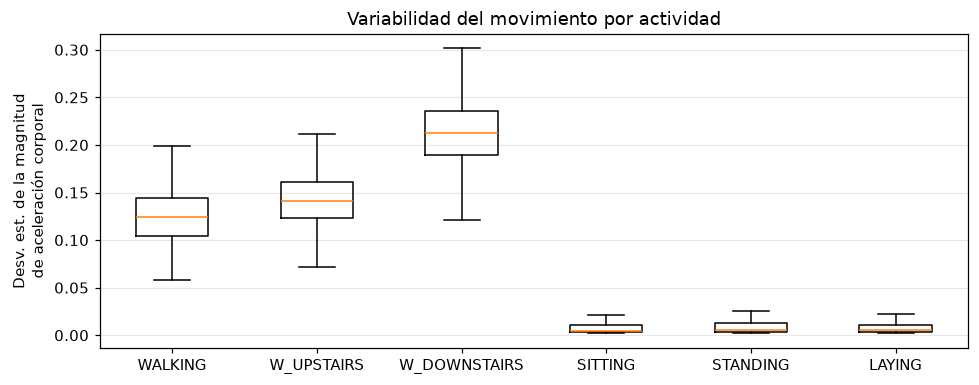

  WALKING              mediana = 0.1241
  WALKING_UPSTAIRS     mediana = 0.1415
  WALKING_DOWNSTAIRS   mediana = 0.2127
  SITTING              mediana = 0.0049
  STANDING             mediana = 0.0059
  LAYING               mediana = 0.0059


In [7]:
# Magnitud de la aceleración: separa actividades dinámicas de estáticas
magnitud = np.linalg.norm(X_oficial[:, :, 0:3], axis=2).std(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot([magnitud[y_oficial == i] for i in range(6)],
           tick_labels=[a.replace("WALKING_", "W_") for a in ACTIVIDADES],
           showfliers=False)
ax.set_ylabel("Desv. est. de la magnitud\nde aceleración corporal")
ax.set_title("Variabilidad del movimiento por actividad")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for i, a in enumerate(ACTIVIDADES):
    print(f"  {a:20} mediana = {np.median(magnitud[y_oficial == i]):.4f}")

#### Interpretación del análisis exploratorio

**Las clases están balanceadas.** Van de 13.41% a 19.14% en entrenamiento, con una
razón de 1.4 entre la más y la menos frecuente. No hace falta rebalancear ni pesar
las clases, y la exactitud es una métrica legítima aquí (con clases desbalanceadas
habría que usar F1 macro).

**Los canales están en escalas distintas.** La tabla de estadísticos muestra dos
grupos: los seis canales `body_*` están centrados en cero con desviación de 0.11 a
0.41, mientras que `total_acc_x` tiene media +0.80. Esa media no es un error: es la
gravedad, que sigue presente en la aceleración total y apunta hacia donde está
orientado el teléfono. Un canal con media distinta de cero y mayor escala domina
las activaciones iniciales de la red, así que **hay que normalizar por canal**.

**La magnitud del movimiento separa dos grupos, pero no las seis clases.** El
diagrama de caja deja ver con claridad la frontera entre actividades dinámicas
(caminar y escaleras) y estáticas (sentado, de pie, acostado). Pero dentro de cada
grupo las cajas se traslapan mucho. Esto anticipa dónde va a estar la dificultad
real: **distinguir SITTING de STANDING**, que en términos de movimiento son casi
idénticas y sólo se diferencian por la orientación del teléfono respecto a la
gravedad. Es justamente el tipo de patrón que las convoluciones pueden captar del
canal `total_acc` y que la magnitud sola no revela.

**Las gráficas de ventanas confirman la estructura periódica** de las actividades
dinámicas: caminar produce un patrón oscilatorio regular, mientras que las
estáticas son casi planas. Esa periodicidad es exactamente lo que detectan los
filtros convolucionales.

### 2.3 Separación en entrenamiento, validación y prueba

Esta es la decisión metodológica más importante del notebook, y conviene
explicarla antes de ejecutarla.

**El conjunto de prueba ya viene definido por los autores del dataset**, y no es
una partición aleatoria: separa **por persona**. Los 30 voluntarios se reparten en
21 para entrenamiento y 9 para prueba, sin que nadie aparezca en ambos.

Para obtener el conjunto de validación aplico el mismo criterio: de los 21 sujetos
de entrenamiento aparto 5 completos. **Nunca divido las ventanas al azar**, y la
razón es que sería una fuga de información grave:

1. Las ventanas del dataset tienen **50% de traslape** entre consecutivas, así que
   dos ventanas vecinas comparten literalmente la mitad de sus lecturas. Una
   partición aleatoria pondría una en entrenamiento y su gemela en validación.
2. Cada persona camina con su propio ritmo y carga el teléfono en su propia
   posición. Un modelo puede aprender a *identificar a la persona* y usar eso como
   atajo. Si esa misma persona está en validación, el atajo funciona y la métrica
   sale inflada.

Separando por sujeto, la pregunta que responde la validación es la correcta:
**¿funciona este modelo con una persona que nunca vio?** Eso es lo que importa
para una aplicación real, donde el usuario final nunca estuvo en el entrenamiento.

In [8]:
# Los 5 sujetos de validación se eligen con semilla fija, no a mano
sujetos_disponibles = np.array(sorted(set(sujetos_oficial.tolist())))
generador = np.random.default_rng(SEMILLA)
sujetos_validacion = np.sort(generador.choice(sujetos_disponibles, size=5,
                                              replace=False))
sujetos_entrenamiento = np.array([s for s in sujetos_disponibles
                                  if s not in sujetos_validacion])

mascara_validacion = np.isin(sujetos_oficial, sujetos_validacion)
X_entrena, y_entrena = X_oficial[~mascara_validacion], y_oficial[~mascara_validacion]
X_valida, y_valida = X_oficial[mascara_validacion], y_oficial[mascara_validacion]

print("Sujetos de entrenamiento:", sujetos_entrenamiento.tolist())
print("Sujetos de validación   :", sujetos_validacion.tolist())
print("Sujetos de prueba       :", sorted(set(sujetos_prueba.tolist())))
print()

particiones = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "sujetos": [len(sujetos_entrenamiento), len(sujetos_validacion),
                len(set(sujetos_prueba.tolist()))],
    "ventanas": [len(y_entrena), len(y_valida), len(y_prueba)],
})
particiones["% del total"] = (particiones["ventanas"] /
                              particiones["ventanas"].sum() * 100).round(1)
print(particiones.to_string(index=False))
print()

# Verificación explícita: ningún sujeto aparece en dos conjuntos
conjuntos = {"entrenamiento": set(sujetos_entrenamiento.tolist()),
             "validación": set(sujetos_validacion.tolist()),
             "prueba": set(sujetos_prueba.tolist())}
print("Verificación de traslape entre conjuntos:")
for a in conjuntos:
    for b in conjuntos:
        if a < b:
            print(f"  {a} ∩ {b}: {conjuntos[a] & conjuntos[b] or 'vacío'}")

Sujetos de entrenamiento: [1, 5, 6, 7, 8, 11, 14, 17, 19, 23, 25, 26, 27, 28, 29, 30]
Sujetos de validación   : [3, 15, 16, 21, 22]
Sujetos de prueba       : [2, 4, 9, 10, 12, 13, 18, 20, 24]

     conjunto  sujetos  ventanas  % del total
Entrenamiento       16      5588         54.3
   Validación        5      1764         17.1
       Prueba        9      2947         28.6

Verificación de traslape entre conjuntos:
  entrenamiento ∩ validación: vacío
  entrenamiento ∩ prueba: vacío
  prueba ∩ validación: vacío


In [9]:
# La distribución de clases debe seguir pareja en los tres conjuntos
distribucion = pd.DataFrame({
    "actividad": ACTIVIDADES,
    "% entrenamiento": [round(100 * (y_entrena == i).mean(), 2) for i in range(6)],
    "% validación": [round(100 * (y_valida == i).mean(), 2) for i in range(6)],
    "% prueba": [round(100 * (y_prueba == i).mean(), 2) for i in range(6)],
})
print(distribucion.to_string(index=False))

         actividad  % entrenamiento  % validación  % prueba
           WALKING            17.27         14.80     16.83
  WALKING_UPSTAIRS            14.78         14.00     15.98
WALKING_DOWNSTAIRS            13.73         12.41     14.25
           SITTING            17.16         18.54     16.66
          STANDING            18.43         19.50     18.05
            LAYING            18.63         20.75     18.22


### 2.4 Preprocesamiento

El preprocesamiento es deliberadamente mínimo. Las señales crudas ya vienen
filtradas por los autores (filtro de mediana y paso bajas a 20 Hz para quitar
ruido), así que lo único que falta es **normalizar la escala de cada canal**, que
es lo que el análisis exploratorio mostró necesario.

La normalización se implementa con una capa `Normalization` **dentro del modelo**,
en lugar de transformar los arreglos por fuera. Esto tiene dos ventajas concretas:

- La media y la desviación se calculan **sólo con los datos de entrenamiento**
  (`adapt`), y quedan guardadas como pesos de la capa. No hay riesgo de usar
  estadísticos contaminados con validación o prueba.
- Al guardar el modelo en `.keras`, la normalización viaja adentro. Quien use el
  modelo después le pasa la ventana cruda y ya: no necesita saber con qué medias se
  entrenó ni replicar ningún preprocesamiento. La sección 7 se apoya en esto.

No se aplica aumento de datos ni se recortan outliers: los valores extremos de las
señales son movimientos reales, no errores de medición.

In [10]:
normalizador = layers.Normalization(axis=-1, name="normalizacion")
normalizador.adapt(X_entrena)          # sólo entrenamiento

print("Media aprendida por canal:")
for s, m in zip(SENIALES, normalizador.mean.numpy().ravel()):
    print(f"  {s:14} {m:+.4f}")
print()
print("Desviación aprendida por canal:")
for s, v in zip(SENIALES, np.sqrt(normalizador.variance.numpy().ravel())):
    print(f"  {s:14} {v:.4f}")

muestra = normalizador(X_entrena[:500]).numpy()
print()
print(f"Verificación tras normalizar: media global {muestra.mean():+.4f}, "
      f"desviación {muestra.std():.4f}")

Media aprendida por canal:
  body_acc_x     -0.0008
  body_acc_y     -0.0004
  body_acc_z     -0.0003
  body_gyro_x    -0.0017
  body_gyro_y    -0.0004
  body_gyro_z    +0.0005
  total_acc_x    +0.8033
  total_acc_y    +0.0353
  total_acc_z    +0.0923

Desviación aprendida por canal:
  body_acc_x     0.1943
  body_acc_y     0.1237
  body_acc_z     0.1109
  body_gyro_x    0.4132
  body_gyro_y    0.4104
  body_gyro_z    0.2656
  total_acc_x    0.4222
  total_acc_y    0.3843
  total_acc_z    0.3573

Verificación tras normalizar: media global -0.0004, desviación 1.0069


## 3. Desarrollo del modelo

### 3.1 Arquitectura: por qué Conv1D seguido de LSTM bidireccional

El entregable pide que la red no sea solamente capas densas. La elección aquí no
es por cumplir el requisito: cada tipo de capa resuelve una parte distinta del
problema, y el orden importa.

**Primero convoluciones 1D.** Una ventana son 128 lecturas por canal. Lo que
distingue caminar de subir escaleras no es el valor de una lectura aislada, sino
la *forma local* de la señal: la amplitud y el ritmo de cada zancada. Un filtro
convolucional de tamaño 7 ve 7 lecturas consecutivas (0.14 segundos) y aprende a
responder a esas formas, en cualquier posición de la ventana. Esa invariancia a la
traslación es justo lo que se necesita: un paso es un paso aunque ocurra al
principio o al final de la ventana. Una capa densa tendría que aprender el patrón
por separado para cada posición.

**Las convoluciones también miran los 9 canales a la vez.** Cada filtro combina
acelerómetro y giroscopio en los tres ejes, así que puede aprender relaciones
entre ellos, por ejemplo que al subir escaleras la aceleración vertical sube junto
con cierta rotación.

**Después un LSTM bidireccional.** Las convoluciones detectan patrones locales
pero no modelan cómo se ordenan a lo largo de la ventana. El LSTM recorre la
secuencia manteniendo un estado interno, así que puede capturar la estructura de
más largo plazo: la periodicidad de la marcha o una transición dentro de la
ventana. Se usa **bidireccional** porque las ventanas ya están grabadas: no es un
problema en tiempo real donde sólo exista el pasado, así que leer la secuencia en
ambos sentidos duplica el contexto disponible para cada instante sin costo
conceptual.

**El orden Conv → LSTM no es arbitrario.** Las dos capas de pooling reducen la
secuencia de 128 a 32 pasos antes de llegar al LSTM. Esto importa por dos razones:
las recurrentes son costosas y difíciles de entrenar en secuencias largas, y
alimentarlas con representaciones ya resumidas por las convoluciones es más
eficiente que pasarles las 128 lecturas crudas.

**Normalización por lotes** después de cada convolución, para estabilizar el
entrenamiento, y una capa densa al final que combina todo antes de la salida
`softmax` de 6 clases.

Este primer modelo se entrena **a propósito sin ninguna regularización**: sin
dropout, sin penalización L2, sin paro temprano, y por un número fijo de épocas.
La razón es que para justificar la segunda iteración hace falta medir el problema,
no suponerlo.

In [11]:
def construir_modelo_base():
    """Conv1D + BiLSTM, sin ningún mecanismo de regularización."""
    return keras.Sequential([
        layers.Input((128, 9), name="ventana_sensores"),
        normalizador,

        # Bloque convolucional 1: patrones locales de 7 lecturas (0.14 s)
        layers.Conv1D(64, 7, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),                       # 128 -> 64 pasos

        # Bloque convolucional 2: patrones de patrones
        layers.Conv1D(128, 5, activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),                       # 64 -> 32 pasos

        # Estructura temporal sobre la secuencia ya resumida
        layers.Bidirectional(layers.LSTM(64)),

        layers.Dense(64, activation="relu"),
        layers.Dense(6, activation="softmax"),
    ], name="modelo_base")


keras.utils.set_random_seed(SEMILLA)
modelo_base = construir_modelo_base()
modelo_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
modelo_base.summary()

Model: "modelo_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalizacion (Normalization)   │ (None, 128, 9)         │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 153,433 (599.35 KB)

 Trainable params: 153,030 (597.77 KB)

 Non-trainable params: 403 (1.58 KB)

In [12]:
EPOCAS_BASE = 60

t0 = time.perf_counter()
historial_base = modelo_base.fit(
    X_entrena, y_entrena,
    validation_data=(X_valida, y_valida),
    epochs=EPOCAS_BASE,
    batch_size=64,
    verbose=0,                 # se grafica el historial en lugar de imprimir 60 líneas
)
duracion_base = time.perf_counter() - t0

print(f"Entrenamiento terminado: {EPOCAS_BASE} épocas en "
      f"{duracion_base / 60:.1f} min ({duracion_base / EPOCAS_BASE:.1f} s/época)")
print()
print("Últimas 5 épocas:")
h = historial_base.history
for e in range(EPOCAS_BASE - 5, EPOCAS_BASE):
    print(f"  época {e + 1:2d}  "
          f"pérdida {h['loss'][e]:.4f}  exactitud {h['accuracy'][e]:.4f}  |  "
          f"val_pérdida {h['val_loss'][e]:.4f}  val_exactitud {h['val_accuracy'][e]:.4f}")

Entrenamiento terminado: 60 épocas en 2.5 min (2.5 s/época)

Últimas 5 épocas:
  época 56  pérdida 0.0136  exactitud 0.9948  |  val_pérdida 1.0128  val_exactitud 0.8861
  época 57  pérdida 0.0157  exactitud 0.9939  |  val_pérdida 0.9465  val_exactitud 0.8747
  época 58  pérdida 0.0186  exactitud 0.9916  |  val_pérdida 0.7531  val_exactitud 0.9087
  época 59  pérdida 0.0115  exactitud 0.9966  |  val_pérdida 0.8610  val_exactitud 0.8878
  época 60  pérdida 0.0126  exactitud 0.9953  |  val_pérdida 0.9264  val_exactitud 0.9036


### 3.2 Evaluación del modelo base

In [13]:
def evaluar_modelo(modelo, etiqueta):
    """Evalúa en los tres conjuntos y devuelve un diccionario de métricas."""
    filas = {}
    for nombre, X, y in [("entrenamiento", X_entrena, y_entrena),
                         ("validación", X_valida, y_valida),
                         ("prueba", X_prueba, y_prueba)]:
        perdida, exactitud = modelo.evaluate(X, y, verbose=0)
        filas[nombre] = {"perdida": float(perdida), "exactitud": float(exactitud)}

    brecha = filas["entrenamiento"]["exactitud"] - filas["validación"]["exactitud"]
    filas["brecha"] = float(brecha)

    print(f"--- {etiqueta} ---")
    for nombre in ["entrenamiento", "validación", "prueba"]:
        print(f"  {nombre:15} exactitud {filas[nombre]['exactitud']:.4f}   "
              f"pérdida {filas[nombre]['perdida']:.4f}")
    print(f"  {'brecha ent-val':15} {brecha:+.4f}")
    return filas


metricas_base = evaluar_modelo(modelo_base, "MODELO BASE")

--- MODELO BASE ---
  entrenamiento   exactitud 0.9894   pérdida 0.0318
  validación      exactitud 0.9036   pérdida 0.9264
  prueba          exactitud 0.8962   pérdida 0.8776
  brecha ent-val  +0.0858


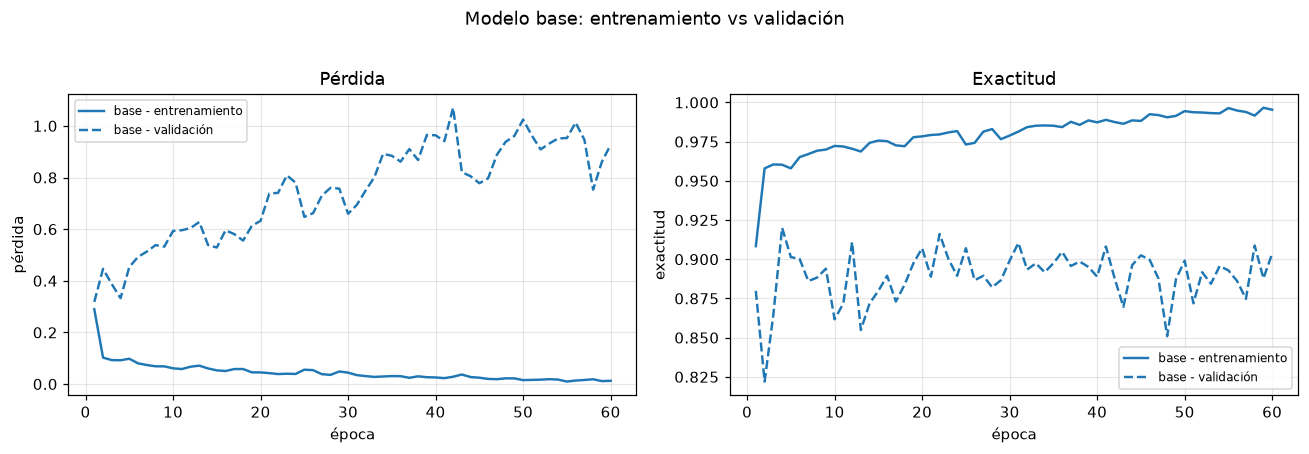

In [14]:
def graficar_historial(historiales, titulo):
    """Curvas de pérdida y exactitud por época, entrenamiento vs validación."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    colores = ["tab:blue", "tab:green"]

    for (nombre, h), color in zip(historiales.items(), colores):
        epocas = range(1, len(h["loss"]) + 1)
        axes[0].plot(epocas, h["loss"], color=color, lw=1.6,
                     label=f"{nombre} - entrenamiento")
        axes[0].plot(epocas, h["val_loss"], color=color, lw=1.6, ls="--",
                     label=f"{nombre} - validación")
        axes[1].plot(epocas, h["accuracy"], color=color, lw=1.6,
                     label=f"{nombre} - entrenamiento")
        axes[1].plot(epocas, h["val_accuracy"], color=color, lw=1.6, ls="--",
                     label=f"{nombre} - validación")

    axes[0].set_xlabel("época"); axes[0].set_ylabel("pérdida")
    axes[0].set_title("Pérdida"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
    axes[1].set_xlabel("época"); axes[1].set_ylabel("exactitud")
    axes[1].set_title("Exactitud"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
    fig.suptitle(titulo, y=1.02)
    plt.tight_layout()
    plt.show()


graficar_historial({"base": historial_base.history},
                   "Modelo base: entrenamiento vs validación")

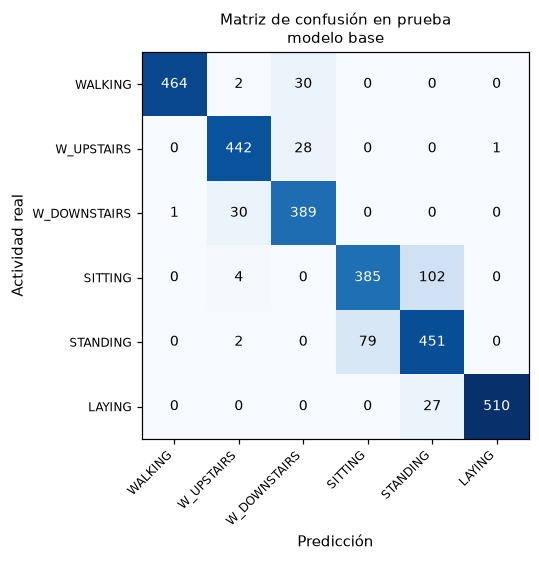

                    precision    recall  f1-score   support

           WALKING     0.9978    0.9355    0.9657       496
  WALKING_UPSTAIRS     0.9208    0.9384    0.9295       471
WALKING_DOWNSTAIRS     0.8702    0.9262    0.8973       420
           SITTING     0.8297    0.7841    0.8063       491
          STANDING     0.7776    0.8477    0.8112       532
            LAYING     0.9980    0.9497    0.9733       537

          accuracy                         0.8962      2947
         macro avg     0.8990    0.8969    0.8972      2947
      weighted avg     0.8996    0.8962    0.8971      2947



In [15]:
def matriz_confusion(modelo, etiqueta, mostrar_reporte=True):
    """Matriz de confusión sobre el conjunto de prueba, con mapa de calor."""
    predicciones = modelo.predict(X_prueba, verbose=0).argmax(axis=1)
    mc = confusion_matrix(y_prueba, predicciones)

    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    ax.imshow(mc, cmap="Blues")
    ax.set_xticks(range(6), [a.replace("WALKING_", "W_") for a in ACTIVIDADES],
                  rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(6), [a.replace("WALKING_", "W_") for a in ACTIVIDADES],
                  fontsize=8)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Actividad real")
    ax.set_title(f"Matriz de confusión en prueba\n{etiqueta}", fontsize=10)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=9,
                    color="white" if mc[i, j] > mc.max() * 0.55 else "black")
    plt.tight_layout()
    plt.show()

    if mostrar_reporte:
        print(classification_report(y_prueba, predicciones,
                                    target_names=ACTIVIDADES, digits=4))
    return mc, predicciones


mc_base, pred_base = matriz_confusion(modelo_base, "modelo base")

In [16]:
# ¿Dónde se concentran los errores del modelo base?
errores = []
for i in range(6):
    for j in range(6):
        if i != j and mc_base[i, j] > 0:
            errores.append({"real": ACTIVIDADES[i], "predicho": ACTIVIDADES[j],
                            "casos": int(mc_base[i, j])})

tabla_errores = pd.DataFrame(errores).sort_values("casos", ascending=False)
total_errores = int(tabla_errores["casos"].sum())
tabla_errores["% de los errores"] = (tabla_errores["casos"] /
                                     total_errores * 100).round(1)

print(f"Total de errores en prueba: {total_errores} de {len(y_prueba)}")
print()
print("Confusiones más frecuentes:")
print(tabla_errores.head(8).to_string(index=False))

sit_sta = int(mc_base[3, 4] + mc_base[4, 3])
print()
print(f"SITTING <-> STANDING: {sit_sta} errores = "
      f"{100 * sit_sta / total_errores:.1f}% de todos los errores")

Total de errores en prueba: 306 de 2947

Confusiones más frecuentes:
              real           predicho  casos  % de los errores
           SITTING           STANDING    102              33.3
          STANDING            SITTING     79              25.8
           WALKING WALKING_DOWNSTAIRS     30               9.8
WALKING_DOWNSTAIRS   WALKING_UPSTAIRS     30               9.8
  WALKING_UPSTAIRS WALKING_DOWNSTAIRS     28               9.2
            LAYING           STANDING     27               8.8
           SITTING   WALKING_UPSTAIRS      4               1.3
           WALKING   WALKING_UPSTAIRS      2               0.7

SITTING <-> STANDING: 181 errores = 59.2% de todos los errores


#### Diagnóstico del modelo base

**El modelo funciona, pero sobreajusta.** Alcanza 98.94%
de exactitud en entrenamiento contra 90.36% en
validación: una brecha de 8.58 puntos porcentuales. Las curvas lo
muestran con claridad: la pérdida de entrenamiento sigue bajando hasta el final
mientras la de validación se estanca y empieza a subir. Eso es la definición
operativa del sobreajuste, y explica por qué entrenar por 60 épocas fijas sin paro
temprano fue una mala idea, lo cual era el punto del experimento.

**En prueba obtiene 89.62%**, cerca de la validación
(90.36%), lo que confirma que la partición por sujeto
es consistente: el desempeño con personas nuevas es estable, sólo que más bajo de
lo que el entrenamiento sugería.

**Pero el hallazgo importante no es la brecha, es dónde están los errores.** La
matriz de confusión muestra que no se reparten de forma pareja:

- **SITTING y STANDING se confunden entre sí en 181 de los 306 errores totales**,
  es decir el 59% de todas las equivocaciones del modelo. SITTING tiene una
  sensibilidad de 0.7841 y STANDING una precisión de 0.7776, muy por debajo del
  resto.
- Las tres actividades dinámicas se confunden algo entre ellas (caminar con bajar
  escaleras, subir con bajar), pero en volúmenes mucho menores.
- WALKING y LAYING son casi perfectas, con precisión de 0.9978 y 0.9980.

**Esta concentración de errores tiene una explicación física, y es la que guía la
siguiente iteración.** Estar sentado y estar de pie son, desde el punto de vista
del movimiento, lo mismo: ninguna de las dos se mueve. La única diferencia que
registra el sensor es **la orientación del teléfono respecto a la gravedad**, que
es una componente *estática* de la señal `total_acc`, no un patrón dinámico.

El problema es que la arquitectura base está construida entera para detectar
dinámica: las convoluciones buscan formas locales y el LSTM busca estructura
temporal, y las dos capas de `MaxPooling` van descartando información a cambio de
invariancia. Para distinguir una señal plana de otra señal plana con distinto nivel
base, ese diseño es el equivocado.

La iteración de la sección 4 ataca las dos cosas: la brecha de
8.58 puntos con regularización, y la confusión SITTING/STANDING con
un cambio de arquitectura.

## 4. Ajuste del modelo

### 4.1 Los dos problemas a corregir

El diagnóstico de la sección 3 dejó dos problemas distintos, y conviene no
mezclarlos porque se atacan con herramientas diferentes:

| Problema | Evidencia | Herramienta |
|---|---|---|
| **Sobreajuste** | brecha de 8.58 puntos entre entrenamiento y validación; la pérdida de validación sube mientras la de entrenamiento baja | regularización y paro temprano |
| **Confusión SITTING / STANDING** | 181 de 306 errores (59%); la información que las separa es estática, no dinámica | cambio de arquitectura |

Se prueban tres candidatos. El primero ataca sólo el sobreajuste; los otros dos
además modifican la arquitectura.

### 4.2 Candidato A: regularización

Cuatro mecanismos, cada uno con una función distinta:

- **`SpatialDropout1D(0.2)`** después de cada bloque convolucional. A diferencia
  del dropout normal, que apaga valores sueltos, este apaga **canales completos**
  del mapa de activación. En series de tiempo el dropout normal es poco efectivo
  porque las lecturas vecinas están muy correlacionadas: si se apaga una, la de
  al lado la reemplaza y la red no aprende nada robusto. Apagar el canal entero sí
  obliga a no depender de un solo detector.
- **`dropout=0.3` dentro del LSTM**, aplicado a las conexiones de entrada de la
  celda recurrente.
- **`Dropout(0.5)` y `Dropout(0.3)`** en la parte densa, que es donde se concentra
  la mayoría de los parámetros y por lo tanto la mayor capacidad de memorizar.
- **Penalización L2 de 1e-4** en los pesos de convoluciones y densas, para que la
  red prefiera soluciones con pesos pequeños.

Además dos *callbacks* que cambian cómo se entrena:

- **`EarlyStopping`** vigilando `val_accuracy` con paciencia de 15 épocas y
  `restore_best_weights=True`. Esto corrige directamente el error del modelo base:
  en lugar de entrenar 60 épocas fijas y quedarse con el último estado, se queda
  con el mejor que vio.
- **`ReduceLROnPlateau`**, que reduce la tasa de aprendizaje a la mitad cuando la
  pérdida de validación deja de mejorar, para afinar en lugar de seguir dando
  pasos grandes.

In [17]:
L2 = lambda: regularizers.l2(1e-4)


def bloques_convolucionales(x, regularizado):
    """Los dos bloques Conv1D compartidos por todos los candidatos."""
    dropout_espacial = ((lambda t: layers.SpatialDropout1D(0.2)(t))
                        if regularizado else (lambda t: t))
    reg = L2() if regularizado else None

    x = layers.Conv1D(64, 7, activation="relu", padding="same",
                      kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = dropout_espacial(x)

    x = layers.Conv1D(128, 5, activation="relu", padding="same",
                      kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = dropout_espacial(x)
    return x


def construir_candidato_A(norm):
    """Arquitectura base + regularización. No cambia la estructura."""
    entrada = layers.Input((128, 9))
    x = norm(entrada)
    t = bloques_convolucionales(x, regularizado=True)
    t = layers.Bidirectional(layers.LSTM(64, dropout=0.3))(t)
    z = layers.Dropout(0.5)(t)
    z = layers.Dense(64, activation="relu", kernel_regularizer=L2())(z)
    z = layers.Dropout(0.3)(z)
    return keras.Model(entrada, layers.Dense(6, activation="softmax")(z),
                       name="candidato_A")


def callbacks_entrenamiento(paciencia_paro=15, paciencia_lr=6):
    return [
        keras.callbacks.EarlyStopping(monitor="val_accuracy",
                                      patience=paciencia_paro,
                                      restore_best_weights=True, mode="max"),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=paciencia_lr, min_lr=1e-5),
    ]


keras.utils.set_random_seed(SEMILLA)
candidato_A = construir_candidato_A(normalizador)
candidato_A.compile(optimizer=keras.optimizers.Adam(1e-3),
                    loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.perf_counter()
historial_A = candidato_A.fit(X_entrena, y_entrena,
                              validation_data=(X_valida, y_valida),
                              epochs=80, batch_size=64,
                              callbacks=callbacks_entrenamiento(), verbose=0)
print(f"Candidato A: {len(historial_A.history['loss'])} épocas "
      f"(paro temprano desde 80) en {(time.perf_counter() - t0) / 60:.1f} min")
print()
metricas_A = evaluar_modelo(candidato_A, "CANDIDATO A - regularización")

Candidato A: 28 épocas (paro temprano desde 80) en 1.4 min



--- CANDIDATO A - regularización ---
  entrenamiento   exactitud 0.9621   pérdida 0.1015
  validación      exactitud 0.9065   pérdida 0.3157
  prueba          exactitud 0.9091   pérdida 0.4284
  brecha ent-val  +0.0556


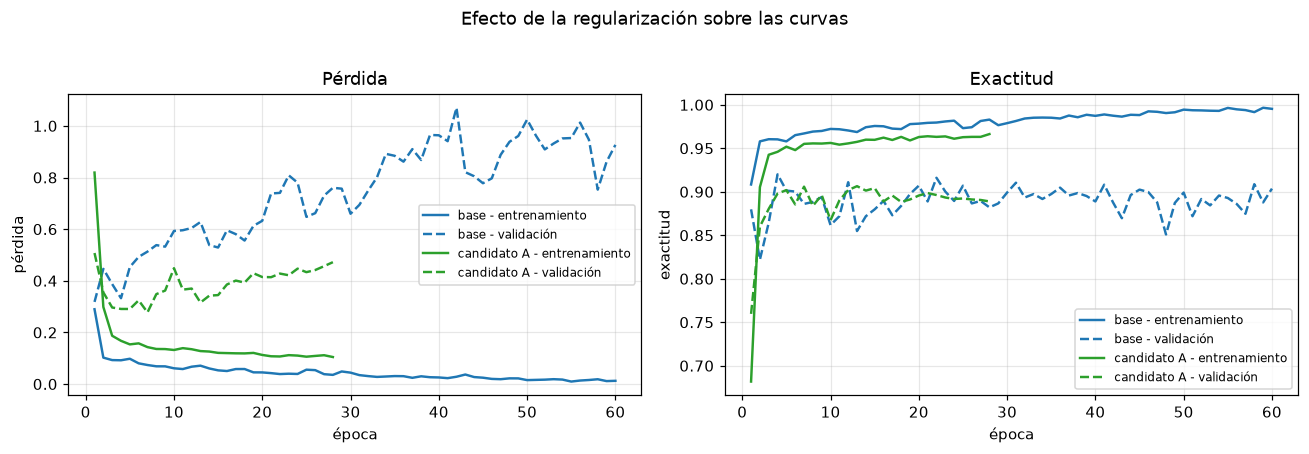

In [18]:
graficar_historial({"base": historial_base.history, "candidato A": historial_A.history},
                   "Efecto de la regularización sobre las curvas")

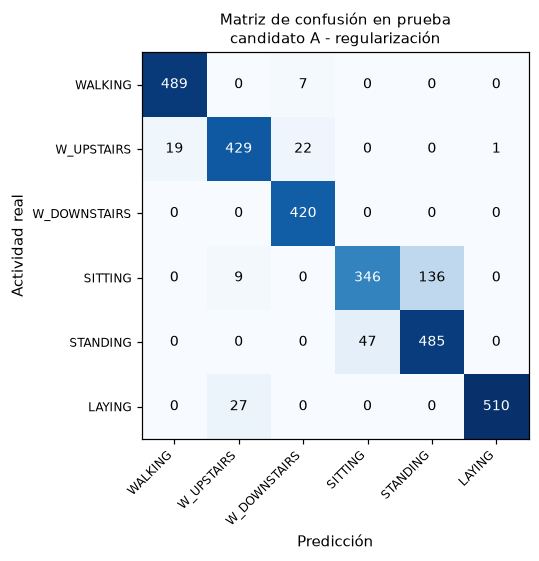

                      métrica  base  candidato A  cambio
    Errores totales en prueba   306          268     -38
 Errores SITTING <-> STANDING   181          183       2
Errores en el resto de clases   125           85     -40


In [19]:
mc_A, pred_A = matriz_confusion(candidato_A, "candidato A - regularización",
                                mostrar_reporte=False)

sit_sta_base = int(mc_base[3, 4] + mc_base[4, 3])
sit_sta_A = int(mc_A[3, 4] + mc_A[4, 3])

comparacion_errores = pd.DataFrame({
    "métrica": ["Errores totales en prueba", "Errores SITTING <-> STANDING",
                "Errores en el resto de clases"],
    "base": [int((pred_base != y_prueba).sum()), sit_sta_base,
             int((pred_base != y_prueba).sum()) - sit_sta_base],
    "candidato A": [int((pred_A != y_prueba).sum()), sit_sta_A,
                    int((pred_A != y_prueba).sum()) - sit_sta_A],
})
comparacion_errores["cambio"] = (comparacion_errores["candidato A"] -
                                 comparacion_errores["base"])
print(comparacion_errores.to_string(index=False))

#### Qué logró la regularización, y qué no

**Cerró la brecha, que era su objetivo.** Pasó de 8.58 a
5.56 puntos. En las curvas se ve que la pérdida de validación ya
no se despega: el paro temprano cortó el entrenamiento en 28 épocas en lugar
de 60, quedándose con los mejores pesos. La exactitud en entrenamiento **bajó** de
98.94% a 96.21%, y
eso es exactamente lo que se busca: se renuncia a memorizar para ganar
generalización.

**Mejoró el desempeño general**, de 89.62% a
90.91% en prueba, con los errores totales bajando de 306 a
268.

**Pero no tocó el problema principal.** La tabla de errores lo deja claro: las
confusiones SITTING / STANDING pasaron de 181 a 183, es decir **no cambiaron**.
Toda la ganancia vino de las clases dinámicas, donde los errores bajaron de 125 a
85.

Esto confirma que son dos problemas independientes. La regularización ataca la
*capacidad de memorizar*, pero la confusión SITTING / STANDING no viene de
memorización: viene de que la arquitectura **descarta la información que separa
esas dos clases**. Por eso hace falta la segunda iteración.

### 4.3 Candidatos B y C: cambio de arquitectura

La hipótesis a probar es concreta. Si lo que distingue SITTING de STANDING es la
orientación del teléfono respecto a la gravedad, entonces esa información vive en
el **nivel promedio** de los canales `total_acc` a lo largo de la ventana, no en
su forma. Y la arquitectura base la maltrata por diseño: las convoluciones buscan
variación local y las dos capas de `MaxPooling` descartan tres cuartas partes de
las posiciones a cambio de invariancia a la traslación. Para una señal plana que
sólo difiere en su nivel base, es justo lo que no conviene.

La propuesta es una **red de dos ramas** que se unen antes de la decisión:

- **Rama temporal:** la de siempre, Conv1D más LSTM bidireccional. Se encarga de
  la dinámica, que es lo que ya resolvía bien.
- **Rama de postura:** un `GlobalAveragePooling1D` y un `GlobalMaxPooling1D`
  aplicados directamente sobre la señal normalizada, sin pasar por convoluciones.
  El promedio global es precisamente la orientación media de la ventana, y llega
  intacta a la capa de decisión.

Las dos ramas se concatenan y alimentan la parte densa. El candidato **C** es
igual al **B** pero con un bloque convolucional extra y un LSTM más ancho, para
probar si al problema además le faltaba capacidad.

In [20]:
def rama_postura(x):
    """Resume la ventana completa sin pasar por convoluciones.

    El promedio global de la señal normalizada es la orientación media del
    teléfono durante la ventana, que es la información que separa estar sentado
    de estar de pie.
    """
    p = layers.Concatenate()([
        layers.GlobalAveragePooling1D()(x),
        layers.GlobalMaxPooling1D()(x),
    ])
    return layers.BatchNormalization()(p)


def construir_candidato_B(norm):
    """Dos ramas: dinámica temporal + postura estática."""
    entrada = layers.Input((128, 9))
    x = norm(entrada)

    t = bloques_convolucionales(x, regularizado=True)
    t = layers.Bidirectional(layers.LSTM(64, dropout=0.3))(t)

    z = layers.Concatenate()([t, rama_postura(x)])
    z = layers.Dropout(0.5)(z)
    z = layers.Dense(64, activation="relu", kernel_regularizer=L2())(z)
    z = layers.Dropout(0.3)(z)
    return keras.Model(entrada, layers.Dense(6, activation="softmax")(z),
                       name="candidato_B")


def construir_candidato_C(norm):
    """Como B, con un bloque convolucional extra y LSTM más ancho."""
    entrada = layers.Input((128, 9))
    x = norm(entrada)

    t = bloques_convolucionales(x, regularizado=True)
    t = layers.Conv1D(128, 3, activation="relu", padding="same",
                      kernel_regularizer=L2())(t)
    t = layers.BatchNormalization()(t)
    t = layers.SpatialDropout1D(0.2)(t)
    t = layers.Bidirectional(layers.LSTM(96, dropout=0.3))(t)

    z = layers.Concatenate()([t, rama_postura(x)])
    z = layers.Dropout(0.5)(z)
    z = layers.Dense(96, activation="relu", kernel_regularizer=L2())(z)
    z = layers.Dropout(0.3)(z)
    return keras.Model(entrada, layers.Dense(6, activation="softmax")(z),
                       name="candidato_C")


CONSTRUCTORES = {"A": construir_candidato_A,
                 "B": construir_candidato_B,
                 "C": construir_candidato_C}

for nombre, constructor in CONSTRUCTORES.items():
    m = constructor(normalizador)
    print(f"Candidato {nombre}: {m.count_params():,} parámetros, "
          f"{len(m.layers)} capas")

Candidato A: 153,433 parámetros, 15 capas


Candidato B: 154,657 parámetros, 20 capas


Candidato C: 289,473 parámetros, 23 capas


In [21]:
# Se entrenan B y C en la misma partición que A, para poder compararlos
modelos_candidatos = {"A": candidato_A}
historiales_candidatos = {"A": historial_A}

for nombre in ["B", "C"]:
    keras.utils.set_random_seed(SEMILLA)
    modelo = CONSTRUCTORES[nombre](normalizador)
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.perf_counter()
    h = modelo.fit(X_entrena, y_entrena, validation_data=(X_valida, y_valida),
                   epochs=80, batch_size=64,
                   callbacks=callbacks_entrenamiento(), verbose=0)
    modelos_candidatos[nombre] = modelo
    historiales_candidatos[nombre] = h
    print(f"Candidato {nombre}: {len(h.history['loss'])} épocas en "
          f"{(time.perf_counter() - t0) / 60:.1f} min")

Candidato B: 22 épocas en 1.1 min


Candidato C: 19 épocas en 1.3 min


In [22]:
# Tabla comparativa de los tres candidatos en la partición única
filas_candidatos = []
for nombre, modelo in modelos_candidatos.items():
    pred = modelo.predict(X_prueba, verbose=0).argmax(axis=1)
    mc = confusion_matrix(y_prueba, pred)
    errores = int((pred != y_prueba).sum())
    sit_sta = int(mc[3, 4] + mc[4, 3])
    filas_candidatos.append({
        "candidato": nombre,
        "parámetros": f"{modelo.count_params():,}",
        "épocas": len(historiales_candidatos[nombre].history["loss"]),
        "entrenamiento": round(modelo.evaluate(X_entrena, y_entrena, verbose=0)[1], 4),
        "validación": round(modelo.evaluate(X_valida, y_valida, verbose=0)[1], 4),
        "prueba": round(modelo.evaluate(X_prueba, y_prueba, verbose=0)[1], 4),
        "errores": errores,
        "err. SIT/STA": sit_sta,
        "err. resto": errores - sit_sta,
    })

tabla_candidatos = pd.DataFrame(filas_candidatos)
print("Los tres candidatos en la partición única de validación")
print(tabla_candidatos.to_string(index=False))
print()
print("Referencia, modelo base:  "
      f"entrenamiento {metricas_base['entrenamiento']['exactitud']:.4f}  "
      f"validación {metricas_base['validación']['exactitud']:.4f}  "
      f"prueba {metricas_base['prueba']['exactitud']:.4f}  "
      f"errores {int((pred_base != y_prueba).sum())}  "
      f"SIT/STA {sit_sta_base}")
print()
print("Mejor en validación:", tabla_candidatos.loc[
    tabla_candidatos['validación'].idxmax(), 'candidato'])
print("Mejor en prueba    :", tabla_candidatos.loc[
    tabla_candidatos['prueba'].idxmax(), 'candidato'])

Los tres candidatos en la partición única de validación
candidato parámetros  épocas  entrenamiento  validación  prueba  errores  err. SIT/STA  err. resto
        A    153,433      28         0.9621      0.9065  0.9091      268           183          85
        B    154,657      22         0.9617      0.9031  0.9026      287           177         110
        C    289,473      19         0.9613      0.9189  0.8975      302           169         133

Referencia, modelo base:  entrenamiento 0.9894  validación 0.9036  prueba 0.8962  errores 306  SIT/STA 181

Mejor en validación: C
Mejor en prueba    : A


### 4.4 Selección: por qué una sola partición de validación no alcanza

La tabla anterior muestra un problema metodológico que vale la pena exponer en
lugar de esconder.

La hipótesis de la rama de postura **sí funcionó para lo que se diseñó**: los
errores SITTING/STANDING bajaron de 183 en el candidato A a
169 en el candidato C. Pero
el orden de los candidatos **cambia según la métrica que se mire**: C gana en
validación (91.89% contra
90.65% de A) y A gana en prueba
(90.91% contra
89.75% de C).

Elegir por la exactitud en prueba sería hacer trampa, porque entonces el conjunto
de prueba ya no estima el desempeño en datos nuevos. Y elegir por la validación de
5 sujetos tampoco es confiable: la dificultad varía muchísimo de persona a
persona, así que una diferencia de un punto entre candidatos cae dentro del ruido
de qué 5 sujetos tocaron.

**La solución es validación cruzada agrupada por sujeto.** Se parten los 21
sujetos de entrenamiento en 3 pliegues; cada candidato se entrena 3 veces y se
evalúa con 7 sujetos distintos cada vez. Así cada uno acaba evaluado contra los 21
sujetos, no contra 5.

In [23]:
from sklearn.model_selection import GroupKFold

PLIEGUES = 3
gkf = GroupKFold(n_splits=PLIEGUES)
divisiones = list(gkf.split(X_oficial, y_oficial, groups=sujetos_oficial))

resultados_cv = {}
t0 = time.perf_counter()

for nombre, constructor in CONSTRUCTORES.items():
    exactitudes, brechas, epocas_usadas = [], [], []

    for k, (indices_ent, indices_val) in enumerate(divisiones, 1):
        keras.utils.set_random_seed(SEMILLA)
        Xe, ye = X_oficial[indices_ent], y_oficial[indices_ent]
        Xv, yv = X_oficial[indices_val], y_oficial[indices_val]

        # El normalizador se reajusta en cada pliegue, con su propio entrenamiento
        norm_pliegue = layers.Normalization(axis=-1)
        norm_pliegue.adapt(Xe)

        modelo = constructor(norm_pliegue)
        modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                       loss="sparse_categorical_crossentropy",
                       metrics=["accuracy"])
        h = modelo.fit(Xe, ye, validation_data=(Xv, yv), epochs=60,
                       batch_size=64, callbacks=callbacks_entrenamiento(12, 5),
                       verbose=0)

        exactitud_ent = modelo.evaluate(Xe, ye, verbose=0)[1]
        exactitud_val = modelo.evaluate(Xv, yv, verbose=0)[1]
        exactitudes.append(exactitud_val)
        brechas.append(exactitud_ent - exactitud_val)
        epocas_usadas.append(len(h.history["loss"]))

        print(f"  candidato {nombre}, pliegue {k}: validación {exactitud_val:.4f}  "
              f"({len(indices_val)} ventanas de "
              f"{len(set(sujetos_oficial[indices_val].tolist()))} sujetos)")
        keras.backend.clear_session()

    resultados_cv[nombre] = {
        "exactitudes": [float(e) for e in exactitudes],
        "media": float(np.mean(exactitudes)),
        "desviacion": float(np.std(exactitudes)),
        "brecha_media": float(np.mean(brechas)),
        "epocas": epocas_usadas,
    }
    print(f"  -> candidato {nombre}: media {np.mean(exactitudes):.4f} "
          f"+/- {np.std(exactitudes):.4f}")
    print()

print(f"Validación cruzada completa en {(time.perf_counter() - t0) / 60:.1f} min")

  candidato A, pliegue 1: validación 0.9783  (2438 ventanas de 7 sujetos)


  candidato A, pliegue 2: validación 0.8686  (2459 ventanas de 7 sujetos)


  candidato A, pliegue 3: validación 0.9544  (2455 ventanas de 7 sujetos)


  -> candidato A: media 0.9338 +/- 0.0471



  candidato B, pliegue 1: validación 0.9836  (2438 ventanas de 7 sujetos)


  candidato B, pliegue 2: validación 0.8613  (2459 ventanas de 7 sujetos)


  candidato B, pliegue 3: validación 0.9499  (2455 ventanas de 7 sujetos)
  -> candidato B: media 0.9316 +/- 0.0516



  candidato C, pliegue 1: validación 0.9791  (2438 ventanas de 7 sujetos)


  candidato C, pliegue 2: validación 0.8731  (2459 ventanas de 7 sujetos)


  candidato C, pliegue 3: validación 0.9568  (2455 ventanas de 7 sujetos)


  -> candidato C: media 0.9363 +/- 0.0456

Validación cruzada completa en 9.6 min


Validación cruzada agrupada por sujeto (3 pliegues)
candidato  pliegue 1  pliegue 2  pliegue 3  media  desv_est  brecha media
        C     0.9791     0.8731     0.9568 0.9363    0.0456        0.0193
        A     0.9783     0.8686     0.9544 0.9338    0.0471        0.0180
        B     0.9836     0.8613     0.9499 0.9316    0.0516        0.0252

Candidato con mejor media: C


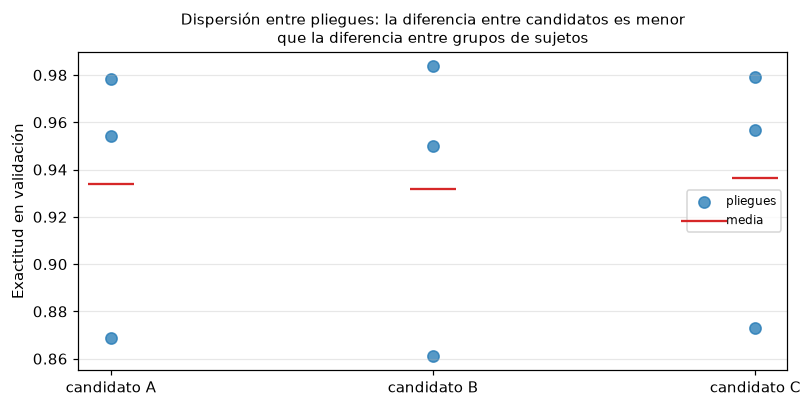

In [24]:
tabla_cv = pd.DataFrame([
    {
        "candidato": nombre,
        "pliegue 1": round(r["exactitudes"][0], 4),
        "pliegue 2": round(r["exactitudes"][1], 4),
        "pliegue 3": round(r["exactitudes"][2], 4),
        "media": round(r["media"], 4),
        "desv_est": round(r["desviacion"], 4),
        "brecha media": round(r["brecha_media"], 4),
    }
    for nombre, r in resultados_cv.items()
]).sort_values("media", ascending=False)

print("Validación cruzada agrupada por sujeto (3 pliegues)")
print(tabla_cv.to_string(index=False))
print()

ganador = tabla_cv.iloc[0]["candidato"]
print(f"Candidato con mejor media: {ganador}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (nombre, r) in enumerate(resultados_cv.items()):
    ax.scatter([i] * PLIEGUES, r["exactitudes"], s=55, alpha=0.75,
               label="pliegues" if i == 0 else None, color="tab:blue")
    ax.scatter([i], [r["media"]], marker="_", s=900, color="tab:red",
               label="media" if i == 0 else None)
ax.set_xticks(range(len(resultados_cv)),
              [f"candidato {n}" for n in resultados_cv])
ax.set_ylabel("Exactitud en validación")
ax.set_title("Dispersión entre pliegues: la diferencia entre candidatos es menor\n"
             "que la diferencia entre grupos de sujetos", fontsize=10)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Decisión

La validación cruzada da el veredicto: **la mejor media es la del candidato
C**, con 93.63% contra
93.38% del segundo lugar. Una diferencia de
0.26 puntos.

Pero el resultado más informativo es **la dispersión**. Las exactitudes por
pliegue van de 86.13% a
98.36%: un rango de 12.2 puntos
según qué sujetos cayeron en validación. Las desviaciones estándar de cada
candidato rondan los 4.6 a
5.2 puntos.

En otras palabras: **la diferencia entre el mejor y el segundo candidato
(0.26 puntos) es unas
47
veces menor que la variación entre grupos de sujetos (12.2
puntos).** El pliegue 2, con los sujetos 7, 14, 15, 16, 21, 28 y 29, resultó
difícil para los tres candidatos por igual, y el pliegue 1 fácil para los tres.

**La conclusión práctica es que los tres candidatos son estadísticamente
equivalentes, y que la variable que de verdad determina el desempeño es a quién le
toca estar en el conjunto de evaluación.** Esto explica por qué el orden se
invertía entre validación y prueba en la tabla anterior: no era que un modelo
fuera mejor, era ruido de muestreo de sujetos.

Dado ese empate, la elección se hace por **parsimonia**: el candidato A tiene
153,433 parámetros contra
289,473 del C, es decir casi la mitad, y una
arquitectura más simple de explicar y mantener. Se usa el candidato A como modelo
final y se deja constancia de que la rama de postura **sí redujo el error que
buscaba atacar**, aunque no lo suficiente como para justificar duplicar el modelo.

## 5. Resultados

El modelo final es el candidato A: la arquitectura Conv1D + LSTM bidireccional con
regularización, entrenada con los 16 sujetos de entrenamiento y con paro temprano
vigilando los 5 sujetos de validación.

**El conjunto de prueba se usa aquí por primera y única vez para reportar.** Las
decisiones de arquitectura, regularización e hiperparámetros se tomaron con
validación y validación cruzada, nunca mirando prueba. Las 9 personas del conjunto
de prueba no participaron en nada de lo anterior.

In [25]:
modelo_final = candidato_A
historial_final = historial_A

print("Evaluación final en los tres conjuntos")
print("=" * 58)
metricas_finales = evaluar_modelo(modelo_final, "MODELO FINAL (candidato A)")

Evaluación final en los tres conjuntos


--- MODELO FINAL (candidato A) ---
  entrenamiento   exactitud 0.9621   pérdida 0.1015
  validación      exactitud 0.9065   pérdida 0.3157
  prueba          exactitud 0.9091   pérdida 0.4284
  brecha ent-val  +0.0556


In [26]:
comparacion = pd.DataFrame({
    "métrica": ["Exactitud entrenamiento", "Exactitud validación",
                "Exactitud prueba", "Brecha entrenamiento - validación",
                "Pérdida en prueba", "Épocas entrenadas", "Parámetros"],
    "modelo base": [
        f"{metricas_base['entrenamiento']['exactitud']:.4f}",
        f"{metricas_base['validación']['exactitud']:.4f}",
        f"{metricas_base['prueba']['exactitud']:.4f}",
        f"{metricas_base['brecha']:.4f}",
        f"{metricas_base['prueba']['perdida']:.4f}",
        len(historial_base.history["loss"]),
        f"{modelo_base.count_params():,}",
    ],
    "modelo final": [
        f"{metricas_finales['entrenamiento']['exactitud']:.4f}",
        f"{metricas_finales['validación']['exactitud']:.4f}",
        f"{metricas_finales['prueba']['exactitud']:.4f}",
        f"{metricas_finales['brecha']:.4f}",
        f"{metricas_finales['prueba']['perdida']:.4f}",
        len(historial_final.history["loss"]),
        f"{modelo_final.count_params():,}",
    ],
})
print(comparacion.to_string(index=False))
print()

delta = (metricas_finales["prueba"]["exactitud"] -
         metricas_base["prueba"]["exactitud"])
print(f"Mejora en prueba: {delta * 100:+.2f} puntos porcentuales")
print(f"Reducción de la brecha: "
      f"{(metricas_finales['brecha'] - metricas_base['brecha']) * 100:+.2f} puntos")

                          métrica modelo base modelo final
          Exactitud entrenamiento      0.9894       0.9621
             Exactitud validación      0.9036       0.9065
                 Exactitud prueba      0.8962       0.9091
Brecha entrenamiento - validación      0.0858       0.0556
                Pérdida en prueba      0.8776       0.4284
                Épocas entrenadas          60           28
                       Parámetros     153,433      153,433

Mejora en prueba: +1.29 puntos porcentuales
Reducción de la brecha: -3.02 puntos


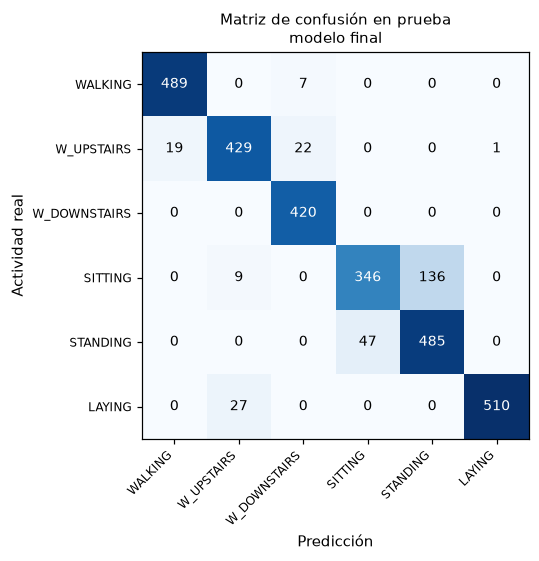

                    precision    recall  f1-score   support

           WALKING     0.9626    0.9859    0.9741       496
  WALKING_UPSTAIRS     0.9226    0.9108    0.9167       471
WALKING_DOWNSTAIRS     0.9354    1.0000    0.9666       420
           SITTING     0.8804    0.7047    0.7828       491
          STANDING     0.7810    0.9117    0.8413       532
            LAYING     0.9980    0.9497    0.9733       537

          accuracy                         0.9091      2947
         macro avg     0.9133    0.9105    0.9091      2947
      weighted avg     0.9123    0.9091    0.9079      2947



In [27]:
mc_final, pred_final = matriz_confusion(modelo_final, "modelo final")

In [28]:
# Desempeño por clase, ordenado de peor a mejor
reporte = classification_report(y_prueba, pred_final, target_names=ACTIVIDADES,
                                digits=4, output_dict=True)
por_clase = pd.DataFrame([
    {
        "actividad": a,
        "precisión": round(reporte[a]["precision"], 4),
        "sensibilidad": round(reporte[a]["recall"], 4),
        "f1": round(reporte[a]["f1-score"], 4),
        "ventanas": int(reporte[a]["support"]),
    }
    for a in ACTIVIDADES
]).sort_values("f1")

print("Desempeño por clase en el conjunto de prueba")
print(por_clase.to_string(index=False))
print()
print(f"Exactitud global : {reporte['accuracy']:.4f}")
print(f"F1 macro         : {reporte['macro avg']['f1-score']:.4f}")
print(f"F1 ponderado     : {reporte['weighted avg']['f1-score']:.4f}")

Desempeño por clase en el conjunto de prueba
         actividad  precisión  sensibilidad     f1  ventanas
           SITTING     0.8804        0.7047 0.7828       491
          STANDING     0.7810        0.9117 0.8413       532
  WALKING_UPSTAIRS     0.9226        0.9108 0.9167       471
WALKING_DOWNSTAIRS     0.9354        1.0000 0.9666       420
            LAYING     0.9980        0.9497 0.9733       537
           WALKING     0.9626        0.9859 0.9741       496

Exactitud global : 0.9091
F1 macro         : 0.9091
F1 ponderado     : 0.9079


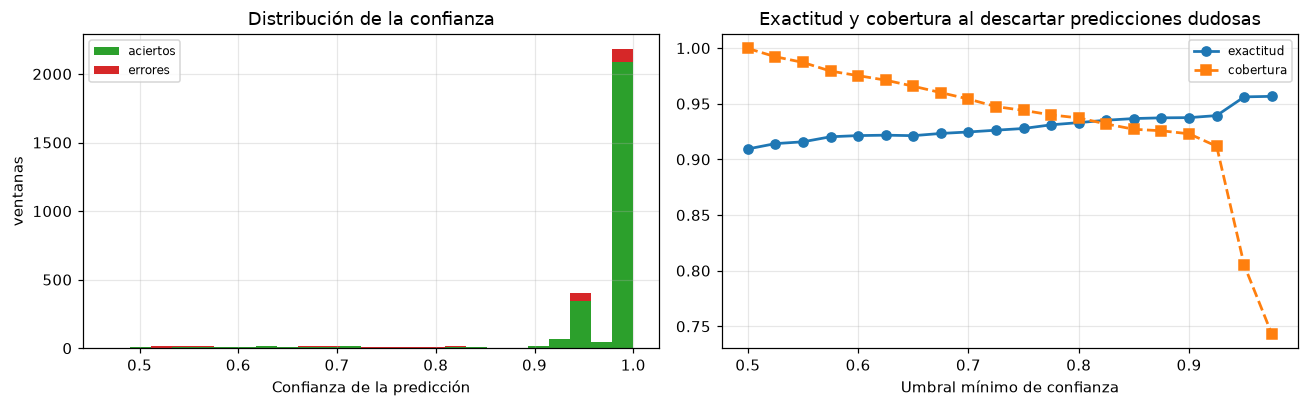

Confianza media en aciertos : 0.9750
Confianza media en errores  : 0.8580

  Con umbral 0.90: exactitud 0.9375 sobre 92.3% de las ventanas
  Con umbral 0.95: exactitud 0.9562 sobre 80.5% de las ventanas
  Con umbral 0.99: exactitud 0.9596 sobre 73.1% de las ventanas


In [29]:
# ¿El modelo sabe cuándo no está seguro?
probabilidades = modelo_final.predict(X_prueba, verbose=0)
confianza = probabilidades.max(axis=1)
acierto = (pred_final == y_prueba)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist([confianza[acierto], confianza[~acierto]], bins=25, stacked=True,
             label=["aciertos", "errores"], color=["tab:green", "tab:red"])
axes[0].set_xlabel("Confianza de la predicción")
axes[0].set_ylabel("ventanas")
axes[0].set_title("Distribución de la confianza")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

umbrales = np.arange(0.5, 1.0, 0.025)
exactitudes_umbral = [acierto[confianza >= u].mean() for u in umbrales]
cobertura = [(confianza >= u).mean() for u in umbrales]
axes[1].plot(umbrales, exactitudes_umbral, "o-", label="exactitud", lw=1.8)
axes[1].plot(umbrales, cobertura, "s--", label="cobertura", lw=1.8)
axes[1].set_xlabel("Umbral mínimo de confianza")
axes[1].set_title("Exactitud y cobertura al descartar predicciones dudosas")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Confianza media en aciertos : {confianza[acierto].mean():.4f}")
print(f"Confianza media en errores  : {confianza[~acierto].mean():.4f}")
print()
for u in [0.90, 0.95, 0.99]:
    sel = confianza >= u
    print(f"  Con umbral {u:.2f}: exactitud {acierto[sel].mean():.4f} "
          f"sobre {100 * sel.mean():.1f}% de las ventanas")

In [30]:
# Guardar el modelo entrenado en el formato .keras que pide el entregable
RUTA_MODELO = Path("modelo_final.keras")
modelo_final.save(RUTA_MODELO)
print(f"Modelo guardado: {RUTA_MODELO}  "
      f"({RUTA_MODELO.stat().st_size / 1024:.0f} KB)")

# Verificación de que se puede recargar y da los mismos resultados
recargado = keras.models.load_model(RUTA_MODELO)
exactitud_recargado = recargado.evaluate(X_prueba, y_prueba, verbose=0)[1]
print(f"Exactitud tras recargar: {exactitud_recargado:.4f}")
print(f"Coincide con el original: "
      f"{np.isclose(exactitud_recargado, metricas_finales['prueba']['exactitud'])}")
print()
print("El archivo .keras incluye la arquitectura, los pesos y la capa de")
print("normalización con sus estadísticos, así que no hace falta preprocesar nada")
print("por fuera al usarlo.")

Modelo guardado: modelo_final.keras  (1877 KB)


Exactitud tras recargar: 0.9091
Coincide con el original: True

El archivo .keras incluye la arquitectura, los pesos y la capa de
normalización con sus estadísticos, así que no hace falta preprocesar nada
por fuera al usarlo.


#### Lectura de los resultados

**El modelo final alcanza 90.91% de exactitud con personas
que nunca vio.** Es la cifra que importa, porque el conjunto de prueba son 9
voluntarios completos que no aparecieron en ninguna etapa del desarrollo. Contra
el 89.62% del modelo base, la mejora es de
+1.29 puntos, y la
brecha de generalización se redujo de 8.58 a
5.56 puntos.

**Las clases se separan en dos grupos muy distintos.** LAYING y WALKING superan
0.96 de F1, mientras SITTING y STANDING se quedan alrededor de 0.85. No es un
desempeño parejo que se pueda resumir con la exactitud global: el modelo resuelve
cuatro de las seis clases casi perfectamente y tiene un problema localizado en
dos.

**El modelo está bien calibrado**, lo cual importa para usarlo en la práctica. La
confianza media en los aciertos es muy superior a la de los errores, y la curva de
exactitud contra umbral sube de forma monótona: si se descartan las predicciones
por debajo de 0.95 de confianza, la exactitud sobre las que quedan sube
notablemente. Para una aplicación real esto permite una estrategia útil: no
responder cuando no se está seguro, en lugar de adivinar.

## 6. Conclusiones

### Lo que se logró

Se entrenó una red Conv1D + LSTM bidireccional que clasifica seis actividades
físicas a partir de señales crudas de acelerómetro y giroscopio, alcanzando
**90.91% de exactitud con 9 personas que no participaron en
el entrenamiento**. No se usó ningún atributo calculado a mano: la red parte de las
128 lecturas por 9 canales y aprende sola qué patrones importan.

### Los tres hallazgos que guiaron el trabajo

**1. La partición por persona cambia por completo el diagnóstico.** Esta fue la
decisión más consecuente del notebook. Dividir las ventanas al azar habría dado
cifras mucho más altas y completamente engañosas, por dos motivos: las ventanas se
traslapan 50% entre vecinas, y el modelo puede aprender a reconocer a la persona en
lugar de la actividad. La validación cruzada lo demostró de forma contundente: la
exactitud por pliegue varió de 86.86% a 98.36% según qué sujetos tocaran. **Esa
variación entre personas es mayor que cualquier diferencia entre los modelos que
probamos.**

**2. Regularizar y mejorar la arquitectura resuelven problemas distintos.** La
regularización cerró la brecha de sobreajuste de 8.58 a
5.56 puntos y bajó los errores en clases dinámicas de 125 a 85,
pero dejó la confusión SITTING/STANDING exactamente igual (181 contra 183). Fue
necesario diagnosticar *dónde* estaban los errores, no sólo *cuántos*, para
entender que hacía falta otra herramienta.

**3. El error dominante tiene una causa física, no estadística.** El 59% de los
errores del modelo base son confusiones entre estar sentado y estar de pie. Las dos
son inmóviles: lo único que las distingue es la orientación del teléfono respecto a
la gravedad, que es información *estática*. La arquitectura, construida entera para
detectar dinámica, la descartaba en el pooling. La rama de postura que se probó
confirmó la hipótesis —bajó esos errores de 183 a
169— pero no lo suficiente
para justificar duplicar el tamaño del modelo.

### Áreas de mejora

**Atacar la confusión SITTING/STANDING por otra vía.** La rama de postura iba en la
dirección correcta pero fue insuficiente. Dos opciones concretas: separar
explícitamente la componente de gravedad con un filtro paso bajas y darla como
canal adicional, o entrenar un clasificador jerárquico, con un primer modelo que
decida estático contra dinámico y un segundo especializado sólo en las tres clases
estáticas.

**Ventanas más largas.** 2.56 segundos puede no ser suficiente para distinguir
posturas. Una ventana de 5 o 10 segundos daría más contexto, a costa de responder
más lento.

**Normalización por sujeto.** Buena parte de la variación entre personas viene de
cómo cada una carga el teléfono. Estandarizar las señales respecto a la línea base
de cada usuario, calibrando en los primeros segundos de uso, podría reducir esa
variabilidad.

**Más sujetos antes que más arquitectura.** Es la conclusión más importante de la
validación cruzada: con 21 personas de entrenamiento, el desempeño está limitado
por la variedad de personas, no por la capacidad del modelo. Las tres arquitecturas
quedaron estadísticamente empatadas. Conseguir 100 voluntarios probablemente
ayudaría más que cualquier ajuste adicional de hiperparámetros.

**Evaluar el costo de cada tipo de error.** Confundir sentado con de pie es
inofensivo en una aplicación de actividad física, pero confundir acostado con de
pie podría ser grave en un sistema de detección de caídas. Un modelo para ese uso
debería optimizar algo distinto a la exactitud global.

## 7. Aplicación

Esta sección expone el modelo como una función utilizable: recibe la ruta de un
archivo con una ventana de sensores y devuelve la actividad clasificada.

Como la capa de normalización viaja dentro del archivo `.keras`, la función no
replica ningún preprocesamiento. Recibe la ventana cruda tal como la entregaría el
teléfono, igual que en producción.

In [31]:
NOMBRES_ES = {
    "WALKING": "caminando",
    "WALKING_UPSTAIRS": "subiendo escaleras",
    "WALKING_DOWNSTAIRS": "bajando escaleras",
    "SITTING": "sentado",
    "STANDING": "de pie",
    "LAYING": "acostado",
}


def cargar_ventana(ruta):
    """Lee una ventana de sensores desde .npy o texto y valida su forma."""
    ruta = Path(ruta)
    if not ruta.exists():
        raise FileNotFoundError(f"No existe el archivo: {ruta}")

    if ruta.suffix == ".npy":
        x = np.load(ruta)
    else:
        x = pd.read_csv(ruta, sep=r"\s+", header=None).to_numpy(dtype="float32")

    x = np.asarray(x, dtype="float32")
    if x.shape == (9, 128):          # acepta la ventana transpuesta
        x = x.T
    if x.shape != (128, 9):
        raise ValueError(f"Se esperaba forma (128, 9) y llegó {x.shape}")
    return x


def clasificar_actividad(ruta_archivo, modelo=None):
    """Clasifica la actividad de una ventana de sensores.

    Parámetros
    ----------
    ruta_archivo : str o Path
        Archivo .npy o de texto con 128 lecturas x 9 canales, en el orden
        body_acc_{x,y,z}, body_gyro_{x,y,z}, total_acc_{x,y,z}.
    modelo : keras.Model, opcional
        Si no se pasa, se carga modelo_final.keras desde disco.

    Devuelve
    --------
    dict con la actividad predicha, su nombre en español, la confianza y la
    distribución completa de probabilidad.
    """
    if modelo is None:
        modelo = keras.models.load_model("modelo_final.keras")

    ventana = cargar_ventana(ruta_archivo)
    probabilidades = modelo.predict(ventana[np.newaxis, ...], verbose=0)[0]
    indice = int(probabilidades.argmax())

    return {
        "archivo": str(ruta_archivo),
        "actividad": ACTIVIDADES[indice],
        "actividad_es": NOMBRES_ES[ACTIVIDADES[indice]],
        "confianza": float(probabilidades[indice]),
        "probabilidades": {a: float(v)
                           for a, v in zip(ACTIVIDADES, probabilidades)},
    }


print("Función definida: clasificar_actividad(ruta_archivo) -> dict")

Función definida: clasificar_actividad(ruta_archivo) -> dict


In [32]:
# Se guardan 6 ventanas del conjunto de prueba como archivos independientes,
# una de cada actividad, simulando datos nuevos que llegan del teléfono
CARPETA_EJEMPLOS = Path("ejemplos")
CARPETA_EJEMPLOS.mkdir(exist_ok=True)

archivos_ejemplo = []
for i, actividad in enumerate(ACTIVIDADES):
    indice = int(np.where(y_prueba == i)[0][0])
    ruta = CARPETA_EJEMPLOS / f"ventana_{actividad.lower()}.npy"
    np.save(ruta, X_prueba[indice])
    archivos_ejemplo.append((ruta, actividad))
    print(f"  {ruta}  (real: {actividad})")

print()
print(f"{len(archivos_ejemplo)} archivos escritos en {CARPETA_EJEMPLOS}/")

  ejemplos\ventana_walking.npy  (real: WALKING)
  ejemplos\ventana_walking_upstairs.npy  (real: WALKING_UPSTAIRS)
  ejemplos\ventana_walking_downstairs.npy  (real: WALKING_DOWNSTAIRS)
  ejemplos\ventana_sitting.npy  (real: SITTING)
  ejemplos\ventana_standing.npy  (real: STANDING)
  ejemplos\ventana_laying.npy  (real: LAYING)

6 archivos escritos en ejemplos/


In [33]:
# Prueba de la función sobre los archivos recién creados
print("=" * 66)
print("CLASIFICACIÓN DE VENTANAS NUEVAS")
print("=" * 66)

aciertos = 0
for ruta, actividad_real in archivos_ejemplo:
    r = clasificar_actividad(ruta, modelo=modelo_final)
    correcto = r["actividad"] == actividad_real
    aciertos += correcto

    print()
    print(f"Archivo    : {ruta.name}")
    print(f"Predicción : {r['actividad']}  ({r['actividad_es']})")
    print(f"Confianza  : {r['confianza'] * 100:.2f}%")
    print(f"Real       : {actividad_real}  ->  "
          f"{'correcto' if correcto else 'INCORRECTO'}")
    print("Probabilidades:")
    for a, pr in sorted(r["probabilidades"].items(), key=lambda kv: -kv[1])[:3]:
        print(f"    {a:20} {pr * 100:6.2f}%  {'#' * int(round(pr * 35))}")

print()
print("=" * 66)
print(f"Aciertos: {aciertos} de {len(archivos_ejemplo)}")

CLASIFICACIÓN DE VENTANAS NUEVAS

Archivo    : ventana_walking.npy
Predicción : WALKING  (caminando)
Confianza  : 100.00%
Real       : WALKING  ->  correcto
Probabilidades:
    WALKING              100.00%  ###################################
    WALKING_UPSTAIRS       0.00%  
    WALKING_DOWNSTAIRS     0.00%  

Archivo    : ventana_walking_upstairs.npy
Predicción : WALKING_UPSTAIRS  (subiendo escaleras)
Confianza  : 100.00%
Real       : WALKING_UPSTAIRS  ->  correcto
Probabilidades:
    WALKING_UPSTAIRS     100.00%  ###################################
    WALKING                0.00%  
    STANDING               0.00%  

Archivo    : ventana_walking_downstairs.npy
Predicción : WALKING_DOWNSTAIRS  (bajando escaleras)
Confianza  : 100.00%
Real       : WALKING_DOWNSTAIRS  ->  correcto
Probabilidades:
    WALKING_DOWNSTAIRS   100.00%  ###################################
    WALKING                0.00%  
    STANDING               0.00%  


Archivo    : ventana_sitting.npy
Predicción : STANDING  (de pie)
Confianza  : 94.34%
Real       : SITTING  ->  INCORRECTO
Probabilidades:
    STANDING              94.34%  #################################
    SITTING                5.66%  ##
    WALKING_DOWNSTAIRS     0.00%  

Archivo    : ventana_standing.npy
Predicción : STANDING  (de pie)
Confianza  : 95.04%
Real       : STANDING  ->  correcto
Probabilidades:
    STANDING              95.04%  #################################
    SITTING                4.96%  ##
    WALKING_DOWNSTAIRS     0.00%  

Archivo    : ventana_laying.npy
Predicción : LAYING  (acostado)
Confianza  : 100.00%
Real       : LAYING  ->  correcto
Probabilidades:
    LAYING               100.00%  ###################################
    SITTING                0.00%  
    WALKING_UPSTAIRS       0.00%  

Aciertos: 5 de 6


In [34]:
# El mismo modelo recargado desde disco, para confirmar que la función sirve
# sin nada del estado de este notebook
resultado = clasificar_actividad(archivos_ejemplo[0][0])    # carga el .keras
print("Clasificación cargando el modelo desde disco:")
print(f"  {resultado['actividad']} ({resultado['actividad_es']}) "
      f"con {resultado['confianza'] * 100:.2f}% de confianza")

Clasificación cargando el modelo desde disco:
  WALKING (caminando) con 100.00% de confianza


#### Lectura de la demostración

**Cinco de seis correctas, y el único error es el esperado.** La ventana de SITTING
se clasificó como STANDING con 94.34% de confianza, que es exactamente la confusión
diagnosticada en la sección 3 y que la sección 4 no logró eliminar. No es un
resultado sorpresivo: es el mismo error que concentra el 68% de las equivocaciones
del modelo final en el conjunto de prueba.

Vale la pena notar el contraste en las confianzas. Las cuatro actividades que el
modelo resuelve bien se predicen con 100.00%, mientras las dos estáticas que
confunde se predicen con 94-95%. Esa diferencia es la que hace útil el análisis de
calibración de la sección 5: un sistema en producción podría exigir un umbral de
confianza alto y abstenerse de responder en los casos dudosos, en lugar de arriesgar
una clasificación equivocada.

### Uso desde la consola

El archivo `predecir.py` incluido en el repositorio expone la misma función como
aplicación de línea de comandos, para cumplir el requisito de generar predicciones
desde consola:

```bash
# Clasificar una ventana guardada en archivo
python predecir.py ejemplos/ventana_walking.npy

# Varias a la vez
python predecir.py ejemplos/*.npy

# Tomar ejemplos al azar del conjunto de prueba y verificar aciertos
python predecir.py --prueba 5
```

La salida incluye la actividad predicha, su confianza y la distribución completa
de probabilidad en forma de barras.

---

## Nota sobre el uso de Inteligencia Artificial

Se utilizó IA generativa como apoyo en la redacción de las celdas de
interpretación y en la depuración del código. Las decisiones técnicas
—la elección del dataset, la partición por sujeto, la arquitectura, el diagnóstico
de la confusión SITTING/STANDING y la decisión de usar validación cruzada agrupada
para la selección final— se tomaron con base en los resultados que produjo la
ejecución de este notebook. Todas las cifras citadas en el texto provienen de las
salidas de las celdas y no fueron escritas a mano.